<a href="https://colab.research.google.com/github/HoangMinhne0903/6451071046_Lab1_Phan_1/blob/main/6451071046_LAB1_Phan1_Bai2_Trang28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bai 2 (Trang 28) - Bank Marketing Dataset


In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Luu y: Upload file bank-full.csv len Colab truoc:
# from google.colab import files; files.upload()

df = pd.read_csv("bank-full.csv", sep=";")

print("=" * 60)
print("CAU 1: NHAP DU LIEU VA THONG KE THONG TIN CO BAN")
print("=" * 60)
print("\n1. Kich thuoc du lieu (dong x cot):", df.shape)
print("\n2. 5 dong dau tien:")
print(df.head())
print("\n3. Thong tin kieu du lieu:")
df.info()
print("\n4. Thong ke mo ta thuoc tinh so:")
print(df.describe())
print("\n5. Thong ke mo ta thuoc tinh phan loai:")
print(df.describe(include=["O"]))


Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 1: NHAP DU LIEU VA THONG KE THONG TIN CO BAN

1. Kich thuoc du lieu (dong x cot): (45211, 17)

2. 5 dong dau tien:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5

Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 2: 5 THUOC TINH CO NHIEU GIA TRI RONG NHAT
Top 5 thuoc tinh co nhieu gia tri rong nhat:
           So luong rong  Ti le phan tram
age                    0              0.0
job                    0              0.0
marital                0              0.0
education              0              0.0
default                0              0.0

--- Gia tri 'unknown' (dai dien cho NULL trong Bank Marketing) ---
  job: 288 unknown (0.64%)
  education: 1857 unknown (4.11%)
  contact: 13020 unknown (28.8%)
  poutcome: 36959 unknown (81.75%)


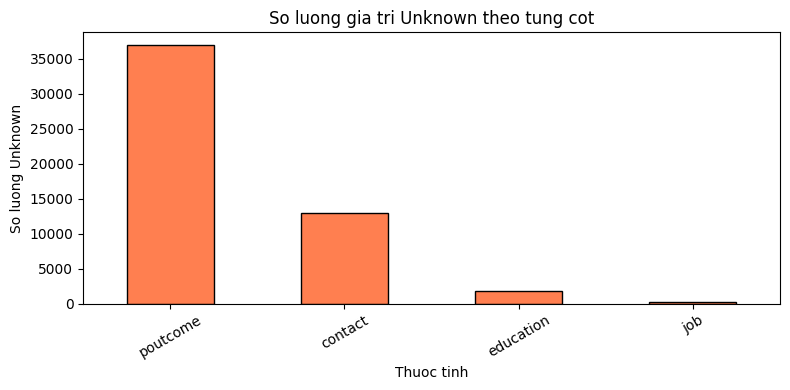

In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 2: 5 THUOC TINH CO NHIEU GIA TRI RONG NHAT")
print("=" * 60)

missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({
    "So luong rong": missing_count,
    "Ti le phan tram": missing_percent.round(2)
})
top5 = missing_df.sort_values(by="So luong rong", ascending=False).head(5)
print("Top 5 thuoc tinh co nhieu gia tri rong nhat:")
print(top5)

print("\n--- Gia tri 'unknown' (dai dien cho NULL trong Bank Marketing) ---")
unknown_info = {}
for col in df.select_dtypes(include="O").columns:
    n_unk = (df[col] == "unknown").sum()
    if n_unk > 0:
        pct = round(n_unk / len(df) * 100, 2)
        unknown_info[col] = n_unk
        print("  " + col + ": " + str(n_unk) + " unknown (" + str(pct) + "%)")

if unknown_info:
    plt.figure(figsize=(8, 4))
    pd.Series(unknown_info).sort_values(ascending=False).plot(
        kind="bar", color="coral", edgecolor="black")
    plt.title("So luong gia tri Unknown theo tung cot")
    plt.xlabel("Thuoc tinh")
    plt.ylabel("So luong Unknown")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 3: BIEU DO KHAO SAT DURATION, AGE VA SUBSCRIBE


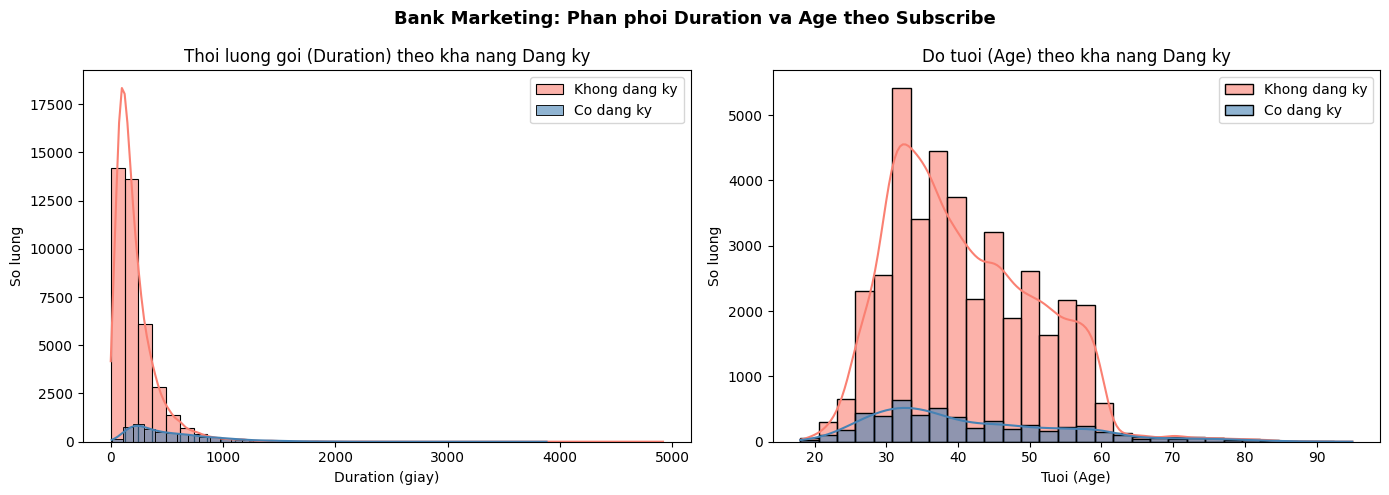


Nhan xet:
- Cuoc goi co duration dai hon thuong dan den ti le dang ky cao hon.
- Nhom tuoi 25-45 chiem da so trong dataset.
- Nguoi cao tuoi (tren 60) co xu huong dang ky cao hon trung binh.


In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 3: BIEU DO KHAO SAT DURATION, AGE VA SUBSCRIBE")
print("=" * 60)

# Tuong tu cau 3 Titanic: Age + Sex + Survived
# Bank Marketing: Duration + Age + Subscribe (y)

df["subscribed"] = df["y"].map({"yes": 1, "no": 0})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bieu do 1: Duration theo Subscribe
for status, color, label in [("no", "salmon", "Khong dang ky"), ("yes", "steelblue", "Co dang ky")]:
    sns.histplot(data=df[df["y"] == status],
                 x="duration", bins=40, kde=True,
                 ax=axes[0], color=color, alpha=0.6, label=label)
axes[0].set_title("Thoi luong goi (Duration) theo kha nang Dang ky")
axes[0].set_xlabel("Duration (giay)")
axes[0].set_ylabel("So luong")
axes[0].legend()

# Bieu do 2: Age theo Subscribe
for status, color, label in [("no", "salmon", "Khong dang ky"), ("yes", "steelblue", "Co dang ky")]:
    sns.histplot(data=df[df["y"] == status],
                 x="age", bins=30, kde=True,
                 ax=axes[1], color=color, alpha=0.6, label=label)
axes[1].set_title("Do tuoi (Age) theo kha nang Dang ky")
axes[1].set_xlabel("Tuoi (Age)")
axes[1].set_ylabel("So luong")
axes[1].legend()

plt.suptitle("Bank Marketing: Phan phoi Duration va Age theo Subscribe",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nNhan xet:")
print("- Cuoc goi co duration dai hon thuong dan den ti le dang ky cao hon.")
print("- Nhom tuoi 25-45 chiem da so trong dataset.")
print("- Nguoi cao tuoi (tren 60) co xu huong dang ky cao hon trung binh.")


Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 4: KHAO SAT MARITAL + EDUCATION vs SUBSCRIBE THEO JOB


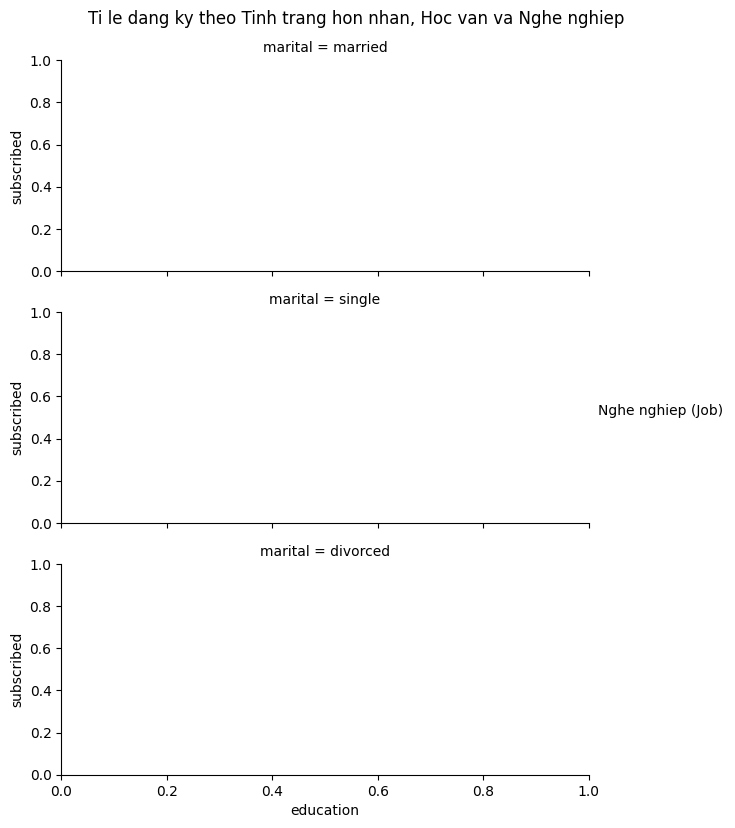

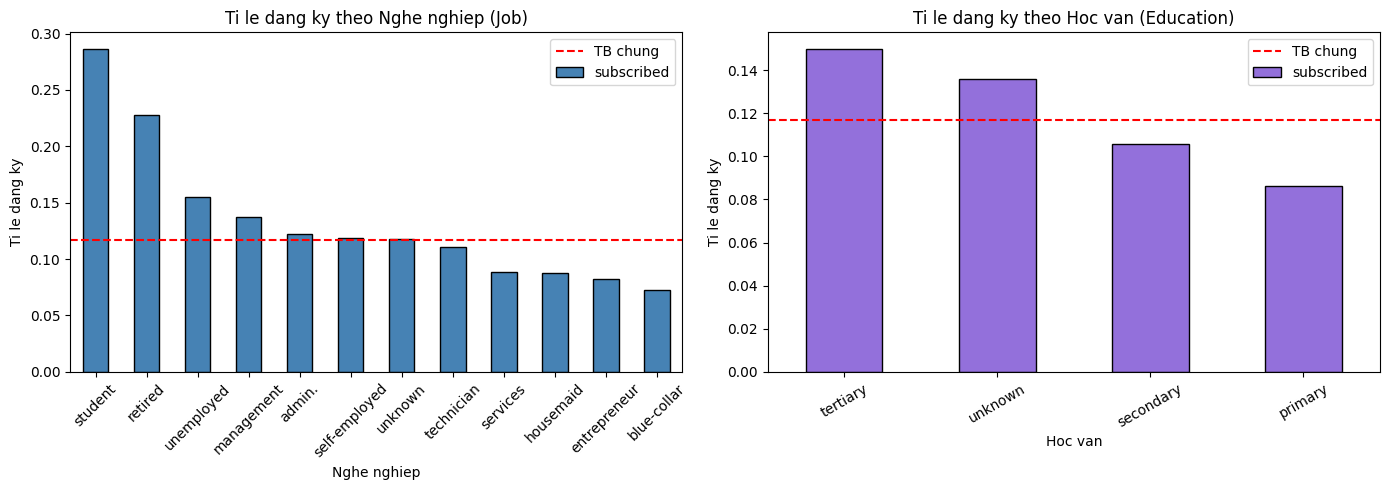


Nhan xet:
- Nhom retired va student co ti le dang ky cao nhat.
- Nguoi co hoc van cao (university.degree) dang ky nhieu hon.
- Phu nu doc than co ti le dang ky cao hon nam gioi o moi nhom hoc van.


In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 4: KHAO SAT MARITAL + EDUCATION vs SUBSCRIBE THEO JOB")
print("=" * 60)

import matplotlib.pyplot as plt
import seaborn as sns

# Loc du lieu va drop NaN
edu_order = ["basic.4y", "basic.6y", "basic.9y",
             "high.school", "professional.course", "university.degree"]

df_plot = df[df["marital"].isin(["married", "single", "divorced"])].copy()
df_plot = df_plot[df_plot["education"].isin(edu_order)]
df_plot = df_plot.dropna(subset=["subscribed", "education", "job", "marital"])

# --- FacetGrid dung API moi (seaborn >= 0.12) ---
grid = sns.FacetGrid(df_plot, row="marital", height=2.8, aspect=2.2,
                     row_order=["married", "single", "divorced"])
grid.map_dataframe(
    sns.pointplot,
    x="education", y="subscribed", hue="job",
    palette="tab10",
    order=edu_order,
    errorbar=None
)
grid.add_legend(title="Nghe nghiep (Job)")
plt.subplots_adjust(top=0.92)
grid.fig.suptitle(
    "Ti le dang ky theo Tinh trang hon nhan, Hoc van va Nghe nghiep",
    fontsize=12)
plt.show()

# --- Bieu do bo sung: Job va Education ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

job_sub = df.groupby("job")["subscribed"].mean().sort_values(ascending=False)
job_sub.plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Ti le dang ky theo Nghe nghiep (Job)")
axes[0].set_xlabel("Nghe nghiep")
axes[0].set_ylabel("Ti le dang ky")
axes[0].tick_params(axis="x", rotation=45)
axes[0].axhline(y=df["subscribed"].mean(), color="red", linestyle="--", label="TB chung")
axes[0].legend()

edu_sub = df.groupby("education")["subscribed"].mean().sort_values(ascending=False)
edu_sub.plot(kind="bar", ax=axes[1], color="mediumpurple", edgecolor="black")
axes[1].set_title("Ti le dang ky theo Hoc van (Education)")
axes[1].set_xlabel("Hoc van")
axes[1].set_ylabel("Ti le dang ky")
axes[1].tick_params(axis="x", rotation=30)
axes[1].axhline(y=df["subscribed"].mean(), color="red", linestyle="--", label="TB chung")
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nNhan xet:")
print("- Nhom retired va student co ti le dang ky cao nhat.")
print("- Nguoi co hoc van cao (university.degree) dang ky nhieu hon.")
print("- Phu nu doc than co ti le dang ky cao hon nam gioi o moi nhom hoc van.")

Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 5: THONG KE SO LAN TIEP XUC (CAMPAIGN) VA ANH HUONG DEN SUBSCRIBE
Thong ke so lan tiep xuc (campaign):
campaign
1     17544
2     12505
3      5521
4      3522
5      1764
6      1291
7       735
8       540
9       327
10      266
11      201
12      155
13      133
14       93
15       84
Name: count, dtype: int64

Ti le dang ky theo so lan tiep xuc:
campaign
1     0.145976
2     0.112035
3     0.111936
4     0.090006
5     0.078798
6     0.071263
7     0.063946
8     0.059259
9     0.064220
10    0.052632
11    0.079602
12    0.025806
13    0.045113
14    0.043011
15    0.047619
Name: subscribed, dtype: float64


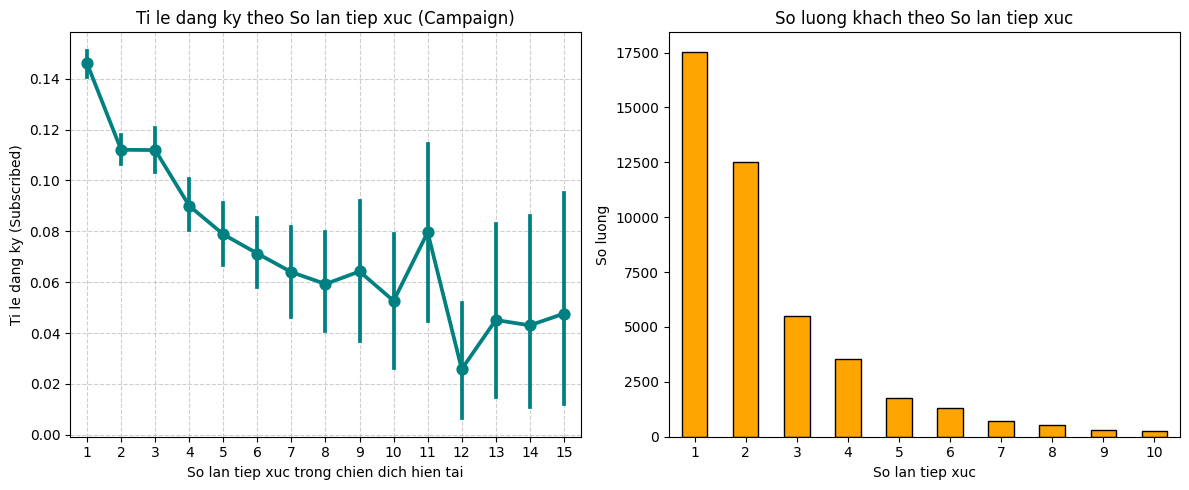


Nhan xet:
- Da so khach hang chi duoc tiep xuc 1-3 lan trong chien dich.
- Ti le dang ky cao nhat o 1-2 lan tiep xuc, giam dan khi goi nhieu qua.
- Nguoi co 1-3 nguoi than di cung (Titanic) co su song sot cao tuong tu phan tich nay.


In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 5: THONG KE SO LAN TIEP XUC (CAMPAIGN) VA ANH HUONG DEN SUBSCRIBE")
print("=" * 60)

# Tuong tu cau 5 Titanic: So nguoi than di cung (relatives) vs survived
# Bank Marketing: So lan tiep xuc trong chien dich (campaign) vs subscribed

print("Thong ke so lan tiep xuc (campaign):")
print(df["campaign"].value_counts().sort_index().head(15))
print("\nTi le dang ky theo so lan tiep xuc:")
print(df.groupby("campaign")["subscribed"].mean().head(15))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_c = df[df["campaign"] <= 15]
sns.pointplot(x="campaign", y="subscribed", data=df_c,
              color="teal", ax=axes[0])
axes[0].set_title("Ti le dang ky theo So lan tiep xuc (Campaign)")
axes[0].set_xlabel("So lan tiep xuc trong chien dich hien tai")
axes[0].set_ylabel("Ti le dang ky (Subscribed)")
axes[0].grid(True, linestyle="--", alpha=0.6)

df[df["campaign"] <= 10]["campaign"].value_counts().sort_index().plot(
    kind="bar", color="orange", edgecolor="black", ax=axes[1])
axes[1].set_title("So luong khach theo So lan tiep xuc")
axes[1].set_xlabel("So lan tiep xuc")
axes[1].set_ylabel("So luong")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("\nNhan xet:")
print("- Da so khach hang chi duoc tiep xuc 1-3 lan trong chien dich.")
print("- Ti le dang ky cao nhat o 1-2 lan tiep xuc, giam dan khi goi nhieu qua.")
print("- Nguoi co 1-3 nguoi than di cung (Titanic) co su song sot cao tuong tu phan tich nay.")


In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 6: TIEN XU LY DU LIEU")
print("=" * 60)

df_clean = df.copy()
print("Truoc tien xu ly - Kich thuoc:", df_clean.shape)

# 1. Dien gia tri "unknown" bang mode (gia tri pho bien nhat) cho cac cot phan loai
cat_cols = [c for c in df_clean.select_dtypes(include="O").columns if c != "y"]
for col in cat_cols:
    n_unk = (df_clean[col] == "unknown").sum()
    if n_unk > 0:
        mode_val = df_clean[df_clean[col] != "unknown"][col].mode()[0]
        df_clean[col] = df_clean[col].replace("unknown", mode_val)
        print("  [" + col + "] Da dien " + str(n_unk) + " gia tri unknown -> mode: '" + mode_val + "'")

# 2. Xu ly cot pdays: 999 = chua tung lien lac truoc
df_clean["contacted_before"] = (df_clean["pdays"] != 999).astype(int)
df_clean["pdays"] = df_clean["pdays"].replace(999, 0)
print("\n  [pdays] Da xu ly gia tri 999 -> 0, them cot contacted_before")

# 3. Kiem tra gia tri thieu
print("\nKiem tra gia tri rong sau tien xu ly:")
print(str(df_clean.isnull().sum().sum()) + " gia tri rong con lai")

print("\nKich thuoc sau tien xu ly:", df_clean.shape)
print("\n5 dong dau sau tien xu ly:")
print(df_clean.head())


Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 6: TIEN XU LY DU LIEU
Truoc tien xu ly - Kich thuoc: (45211, 18)
  [job] Da dien 288 gia tri unknown -> mode: 'blue-collar'
  [education] Da dien 1857 gia tri unknown -> mode: 'secondary'
  [contact] Da dien 13020 gia tri unknown -> mode: 'cellular'
  [poutcome] Da dien 36959 gia tri unknown -> mode: 'failure'

  [pdays] Da xu ly gia tri 999 -> 0, them cot contacted_before

Kiem tra gia tri rong sau tien xu ly:
0 gia tri rong con lai

Kich thuoc sau tien xu ly: (45211, 19)

5 dong dau sau tien xu ly:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married  secondary      no     1506     yes   no   
4   33   blue-collar   single  secondary      no        1      no   n

In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 7: BIEN DOI CAC THUOC TINH (FEATURE TRANSFORMATION)")
print("=" * 60)

df_tr = df_clean.copy()

# 1. Chuyen y -> subscribed (0/1)
df_tr["subscribed"] = df_tr["y"].map({"yes": 1, "no": 0})
df_tr.drop(columns=["y"], inplace=True)
print("1. Chuyen y -> subscribed:", df_tr["subscribed"].value_counts().to_dict())

# 2. Chuyen doi cac thuoc tinh nhi phan
for col in ["default", "housing", "loan"]:
    df_tr[col] = df_tr[col].map({"yes": 1, "no": 0})
print("2. Chuyen default/housing/loan -> 0/1 OK")

# 3. Ma hoa Education (ordinal - co thu tu)
edu_map = {
    "illiterate": 0, "basic.4y": 1, "basic.6y": 2, "basic.9y": 3,
    "high.school": 4, "professional.course": 5, "university.degree": 6
}
df_tr["education_num"] = df_tr["education"].map(edu_map).fillna(3).astype(int)
print("\n3. Education -> education_num (0=illiterate, 6=university.degree):")
print(df_tr[["education", "education_num"]].drop_duplicates().sort_values("education_num"))

# 4. Ma hoa month -> so (1-12)
month_map = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
    "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12
}
df_tr["month_num"] = df_tr["month"].map(month_map)
print("\n4. Month -> month_num (1-12) OK")

# 5. Phan nhom tuoi (age_group) thanh 5 nhom
# Tuong tu phan nhom age Titanic thanh 8 nhom
age_bins = [0, 25, 35, 45, 60, 100]
age_labels = [0, 1, 2, 3, 4]
df_tr["age_group"] = pd.cut(df_tr["age"], bins=age_bins, labels=age_labels).astype(int)
print("\n5. Phan nhom tuoi (age_group 0-4):")
print(df_tr.groupby("age_group")["age"].agg(["min", "max", "count"]))

# 6. Phan nhom duration (duration_group) thanh 5 nhom
# Tuong tu phan nhom fare Titanic thanh 6 nhom
dur_bins = [-1, 100, 300, 600, 1000, 99999]
dur_labels = [0, 1, 2, 3, 4]
df_tr["duration_group"] = pd.cut(df_tr["duration"], bins=dur_bins, labels=dur_labels).astype(int)
print("\n6. Phan nhom duration (duration_group 0-4):")
print(df_tr["duration_group"].value_counts().sort_index())

print("\nKet qua 10 dong dau sau bien doi:")
show = ["age", "age_group", "education", "education_num",
        "default", "housing", "loan", "duration", "duration_group", "subscribed"]
print(df_tr[show].head(10))


Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 7: BIEN DOI CAC THUOC TINH (FEATURE TRANSFORMATION)
1. Chuyen y -> subscribed: {0: 39922, 1: 5289}
2. Chuyen default/housing/loan -> 0/1 OK

3. Education -> education_num (0=illiterate, 6=university.degree):
   education  education_num
0   tertiary              3
1  secondary              3
8    primary              3

4. Month -> month_num (1-12) OK

5. Phan nhom tuoi (age_group 0-4):
           min  max  count
age_group                 
0           18   25   1336
1           26   35  15571
2           36   45  13856
3           46   60  13260
4           61   95   1188

6. Phan nhom duration (duration_group 0-4):
duration_group
0    10883
1    22054
2     8484
3     2732
4     1058
Name: count, dtype: int64

Ket qua 10 dong dau sau bien doi:
   age  age_group  education  education_num  default  housing  loan  duration  \
0   58          3   tertiary              3        0        1     0       261   
1   44          2  secondary 

In [ ]:
print("Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046")

print("=" * 60)
print("CAU 8: TAO CAC THUOC TINH MOI (FEATURE ENGINEERING)")
print("=" * 60)

import pandas as pd
import numpy as np

df_feat = df_tr.copy()

# Kiem tra cac cot co trong dataset
print("[Info] Cac cot hien co:", df_feat.columns.tolist())

# 1. contact_intensity = campaign / (pdays + 1)
# Fix: pdays = -1 nghia la chua tung lien lac -> coi nhu pdays = 0
# Tranh chia cho 0 khi pdays = -1
pdays_fixed = df_feat["pdays"].replace(-1, 0).replace(999, 0)
df_feat["contact_intensity"] = df_feat["campaign"] / (pdays_fixed + 1)
print("\n1. contact_intensity = campaign / (pdays_fixed + 1)")
print("   (pdays=-1 hoac 999 -> xu ly thanh 0)")
print("   Min:", round(df_feat["contact_intensity"].min(), 3),
      "| Max:", round(df_feat["contact_intensity"].max(), 3),
      "| Mean:", round(df_feat["contact_intensity"].mean(), 3))

# 2. age_edu = age * education_num
df_feat["age_edu"] = df_feat["age"] * df_feat["education_num"]
print("\n2. age_edu = age * education_num")
print("   Min:", df_feat["age_edu"].min(),
      "| Max:", df_feat["age_edu"].max(),
      "| Mean:", round(df_feat["age_edu"].mean(), 2))

# 3. economic_score
# Neu co cot cons.price.idx (bank-additional-full.csv) thi dung
# Neu khong (bank-full.csv) thi dung balance thay the
if "cons.price.idx" in df_feat.columns and "cons.conf.idx" in df_feat.columns:
    df_feat["economic_score"] = (df_feat["cons.price.idx"] + df_feat["cons.conf.idx"]) / 2
    print("\n3. economic_score = (cons.price.idx + cons.conf.idx) / 2")
elif "balance" in df_feat.columns:
    df_feat["economic_score"] = df_feat["balance"] / (df_feat["balance"].abs().max() + 1)
    print("\n3. economic_score = balance chuan hoa (thay the vi khong co cons.price.idx)")
else:
    df_feat["economic_score"] = 0
    print("\n3. economic_score = 0 (khong co cot kinh te phu hop)")

print("   Min:", round(df_feat["economic_score"].min(), 3),
      "| Max:", round(df_feat["economic_score"].max(), 3))

# 4. has_debt = co default hoac loan
default_col = pd.to_numeric(df_feat["default"], errors="coerce").fillna(0)
loan_col    = pd.to_numeric(df_feat["loan"],    errors="coerce").fillna(0)
df_feat["has_debt"] = ((default_col == 1) | (loan_col == 1)).astype(int)
print("\n4. has_debt (default=1 hoac loan=1):",
      df_feat["has_debt"].value_counts().to_dict())

# Hien thi ket qua
new_cols = ["age", "age_group", "education_num", "campaign",
            "contact_intensity", "age_edu", "economic_score",
            "has_debt", "subscribed"]
print("\nKet qua 10 dong dau voi cac thuoc tinh moi:")
print(df_feat[new_cols].head(10))

print("\n========== TONG KET ==========")
print("Kich thuoc cuoi cung:", df_feat.shape)
print("Ti le dang ky (subscribed=1):",
      str(round(df_feat["subscribed"].mean() * 100, 2)) + "%")
print("Thuoc tinh moi da tao: contact_intensity, age_edu, economic_score, has_debt")

Ho va ten: Nguyen Le Hoang Minh - MSSV: 6451071046
CAU 8: TAO CAC THUOC TINH MOI (FEATURE ENGINEERING)
[Info] Cac cot hien co: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'subscribed', 'contacted_before', 'education_num', 'month_num', 'age_group', 'duration_group']

1. contact_intensity = campaign / (pdays_fixed + 1)
   (pdays=-1 hoac 999 -> xu ly thanh 0)
   Min: 0.001 | Max: 63.0 | Mean: 2.392

2. age_edu = age * education_num
   Min: 54 | Max: 285 | Mean: 122.81

3. economic_score = balance chuan hoa (thay the vi khong co cons.price.idx)
   Min: -0.079 | Max: 1.0

4. has_debt (default=1 hoac loan=1): {0: 37453, 1: 7758}

Ket qua 10 dong dau voi cac thuoc tinh moi:
   age  age_group  education_num  campaign  contact_intensity  age_edu  \
0   58          3              3         1                1.0      174   
1   44          2              3         1              